# Experiment: Gesture Classification with Deep Learning

In this experiment, a neural network model is trained with EMG data from the 65HDsEMG database to classify gestures. Here, a subset of the EMG channels is used to have the configuration/organization of that of the armband developed for this project. The data are divided into training and validation data to train the model, and into test data to evaluate the classification performance of the trained model.

# Signal preprocessing

The folowing 4-step preprocessing is applied to the EMG signal data:
1. Rectification
2. Teager-Kaiser Energy Operator (TKE)
3. Moving Average (30 samples)
4. Normalization

The normalization step is applied during the training while the other ones have already been applied to the data. 

## Table of Contents

- [0. Import libraries](#0)
- [1. Config Variables and hyperparameters](#1)
- [2. Load dataset with dataloader](#2)
- [3. Create model to train](#3)
- [4. Training](#4)
- [5. Evaluate best model](#5)
- [6. Save the model in .H5 file](#6)


<a name="0"></a>
# Import Libraries

In [1]:
import os, sys

processing_source_path = os.path.abspath('./../../../Processing/')
if(processing_source_path not in sys.path):
    sys.path.append(processing_source_path)
import ProcessingPipeline as pp

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen
from KerasDataPipeline import KerasDataPipeline

model_source_path = os.path.abspath('./../../../Keras_deep_models/')
if(model_source_path not in sys.path):
    sys.path.append(model_source_path)
from EMGConv2DResNetModel import EMGConv2DResNetModel

dataloader_source_path = os.path.abspath('./../../../Utils/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
import utils as utils
import available_metrics as metrics

In [2]:
import numpy as np
from os.path import join
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import json

In [3]:
import tensorflow as tf
print(tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Currently, memory growth needs to be the same across GPUs
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Memory growth must be set before GPUs have been initialized
    print(e)

2.8.0


2025-08-14 16:15:59.639697: E tensorflow/stream_executor/cuda/cuda_driver.cc:271] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2025-08-14 16:15:59.639748: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:163] no NVIDIA GPU device is present: /dev/nvidia0 does not exist


<a name="1"></a>
# Config Variables and hyperparameters

In [4]:
# model_name = 'EMG65_2D_CNN_multiclass_armband_onesubject20230627_194533'
model_name = None

In [5]:
if model_name is None:
    print('Crate new config model')
    data_params = {
        "checkpoint_path": "trainings/",
        "database_path": "65HD_gestures_comparison2_balanced",
        "training_name": 'EMG65_2D_CNN_multiclass_armband' + datetime.datetime.now().strftime("%Y%m%d_%H%M%S"),
        "img_width": 16,
        "img_height": 8,
        "num_features": 256, #num_samples
        "window_step": 12,
        'armband': False,
        'norm':2, # by channels, each channel belong the time
    }
    training_params = {
        "early_stopping_patient": 10,
        "epochs": 200,
        "batch_size": 256,
        "lr": 0.01,
        #"loss": 'CatCE',
        "loss": 'SparceCatCE',
        "filter_divisor": 4,
    }
    optimizer = tf.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)
    model_params = {
        "model_output_mode": 'multiclass',
        "print_model": True,
        "network_name": 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD',
        "optimizer": optimizer,
        "channels": 128,
    }
    # Combine all categories into a single dictionary
    config_model = {**data_params, **model_params, **training_params}
    
    try:
        with open(join('/root/data/data', config_model['database_path'], 'train', 'dataset_param.json')) as json_file:
            dataset_param = json.load(json_file)
            config_model['num_classes'] = len(dataset_param['dataset']['gestures'])
    except:
         config_model['num_classes'] = 7
else:
    config_path = join('trainings/', model_name, 'training_param.json')
    print('Loading config model from:', config_path)
    with open(config_path) as json_file:
        config_model = json.load(json_file)
    
print(config_model)

Crate new config model
{'checkpoint_path': 'trainings/', 'database_path': '65HD_gestures_comparison2_balanced', 'training_name': 'EMG65_2D_CNN_multiclass_armband20250814_161559', 'img_width': 16, 'img_height': 8, 'num_features': 256, 'window_step': 12, 'armband': False, 'norm': 2, 'model_output_mode': 'multiclass', 'print_model': True, 'network_name': 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD', 'optimizer': <keras.optimizer_v2.gradient_descent.SGD object at 0x7fe3d9a113d0>, 'channels': 128, 'early_stopping_patient': 10, 'epochs': 200, 'batch_size': 256, 'lr': 0.01, 'loss': 'SparceCatCE', 'filter_divisor': 4, 'num_classes': 7}


In [6]:
dataset_path = join('/root/data/data', config_model['database_path'])
num_gestures = config_model['num_classes']
window_size = config_model['num_features']
window_step = config_model['window_step']
img_width = config_model['img_width']
img_height = config_model['img_height']
batch_size = config_model['batch_size']
num_emg_channels = config_model['channels']
armband= config_model['armband']

In [7]:
try:
    with open(join(dataset_path, 'train', 'dataset_param.json')) as json_file:
        dataset_param = json.load(json_file)
        gesture_list = dataset_param['dataset']['gestures']
        print(dataset_param)
except:
    gesture_list =[0, 13, 14, 17, 20, 36, 58, 59, 63, 64]
gesture_list, len(gesture_list)

([0, 13, 14, 17, 20, 36, 58, 59, 63, 64], 10)

In [8]:
config_model['gesture_list'] = gesture_list
config_model['num_classes'] = len(gesture_list)

<a name="2"></a>
# Load dataset with dataloader

In [9]:
num_emg_channels

128

In [10]:
data_processing = pp.ProcessingPipeline([
    pp.NormMinMax(axis=config_model['norm']), # initial shape: (batchsize, img_width*img_height, samples)
    pp.DataReshape((img_width, img_height, window_size)),
    #pp.LabelOneHot(np.sort(gesture_list)) # to multiclass 
    ])

train_dataset = EMGGestureDataGen(join(dataset_path, 'train/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name='65HDsEMG')
val_dataset = EMGGestureDataGen(join(dataset_path, 'val/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name='65HDsEMG')
test_dataset = EMGGestureDataGen(join(dataset_path, 'test/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name='65HDsEMG')

In [11]:
train_dataset[0][0].shape

(256, 16, 8, 256)

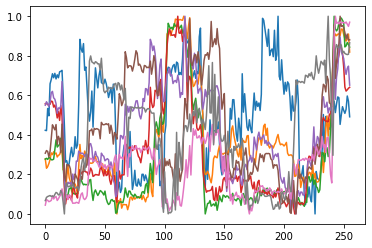

In [12]:
plt.plot(train_dataset[0][0][0,0,:].T)
plt.show()

In [13]:
# # UNCOMMENT TO USE CLASS WEIGHTS
# from sklearn.utils import class_weight

# class_weights = class_weight.compute_class_weight('balanced', classes=np.arange(len(gesture_list)), y=train_dataset.yData)
# config_model['class_weights'] = dict(enumerate(class_weights))

In [14]:
#train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])
#val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])

train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, ])
val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, ])

2025-08-14 16:16:43.614515: I tensorflow/core/platform/cpu_feature_guard.cc:152] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE3 SSE4.1 SSE4.2 AVX
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


<a name="3"></a>
# Create model to train

In [15]:
emg_model = EMGConv2DResNetModel(config_model)
emg_model.load_model()

path False
model compiled
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 16, 8, 256)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d (Conv2D)                (None, 16, 8, 32)    73760       ['input_1[0][0]']                
                                                                                                  
 batch_normalization (BatchNorm  (None, 16, 8, 32)   128         ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                    

<a name="4"></a>
# Training

In [16]:
history = emg_model.train(train_dataset_pipeline.datasetPipeline, val_dataset_pipeline.datasetPipeline)

with open(join(config_model['checkpoint_path'], config_model['network_name'], 'training_param.json'), 'w') as fp:
    json.dump(config_model, fp, indent=4)

no weights
trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD
Epoch 1/200


2025-08-14 16:20:40.755899: W tensorflow/python/util/util.cc:368] Sets are not currently considered sequences, but this may change in the future, so consider avoiding using them.


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD/assets
814/814 - 238s - loss: 1.7889 - accuracy: 0.3716 - val_loss: 1.4511 - val_accuracy: 0.5054 - 238s/epoch - 293ms/step
Epoch 2/200
INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD/assets
814/814 - 234s - loss: 1.4884 - accuracy: 0.4756 - val_loss: 1.0555 - val_accuracy: 0.6425 - 234s/epoch - 288ms/step
Epoch 3/200
814/814 - 211s - loss: 1.2176 - accuracy: 0.5743 - val_loss: 1.1191 - val_accuracy: 0.6235 - 211s/epoch - 259ms/step
Epoch 5/200
INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD/assets
814/814 - 226s - loss: 1.0976 - accuracy: 0.6178 - val_loss: 0.8215 - val_accuracy: 0.7261 - 226s/epoch - 277ms/step
Epoch 6/200
INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD/assets
814/814 - 228s - loss: 0.9927 - accu

TypeError: Object of type SGD is not JSON serializable

In [ ]:
from pandas import read_csv
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.title("Loss")
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.legend()

plt.figure(figsize=(15,5))
plt.title("Accuracy")
plt.plot(history.history['categorical_accuracy'], label='Train')
plt.plot(history.history['val_categorical_accuracy'], label='Validation')
plt.legend()

<a name="5"></a>
# Evaluate best model

In [ ]:
import tensorflow_addons as tfa
# load best model
trained_deep_model = tf.keras.models.load_model(join(config_model['checkpoint_path'] + config_model['network_name']))

<a name="5-1"></a>
### Train Dataset

In [ ]:
test_performance = trained_deep_model.evaluate(train_dataset)
y_train, y_pred = utils.generate_data(train_dataset, trained_deep_model)

In [ ]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_train, y_pred, Get_metrics=True) 

In [ ]:
# available the train data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_train, y_pred, Get_matrix=True)

<a name="5-2"></a>
### Test Dataset

In [ ]:
test_performance = trained_deep_model.evaluate(test_dataset)
y_test, y_pred = utils.generate_data(test_dataset, trained_deep_model)

In [ ]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_test, y_pred, Get_metrics=True) 

In [ ]:
# available the test data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_test, y_pred, Get_matrix=True)

#### Metrics with Average and std for each classes

In [ ]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='Accuracy', method='per_class')

In [ ]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='F1-Score', method='per_class')

#### Mean and std for all Classes 

In [ ]:
metrics_per_class,precision_list,recall_list,f1_score_list,accuracy_list=metrics.model_average_std_metrics(cf_matrix=cfm_deep_model, Get_metrics=True, Verbose=True) 

In [ ]:
metrics_average_and_std_df=pd.DataFrame(data=[precision_list,recall_list,f1_score_list,accuracy_list],
             index=['pr', 're', 'f1', 'acc'],
             columns=['Average','std'])
metrics_average_and_std_df

## ROC

In [ ]:
roc_score_per_class=metrics.get_roc_curve(config_model['gesture_list'], y_test, y_pred ,verbose=True)

In [ ]:
# import mlflow_save_parameters_multiclass 

# mlflow_save_parameters_multiclass.save_data_in_mlflow("65HDsEMG_multiclass_armband", config_model, test_metric, data_processing.getProcessingNameList())

<a name="6"></a>
## Save the model in .H5 file

In [ ]:
trained_deep_model.save(config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5')